In [1]:

import yfinance as yf
from datetime import date

# FIX: end=date.today() instead of hardcoded "2026-06-12"
data = yf.download("OGDC.KA", start="2023-01-01", end=date.today())
if hasattr(data.columns, 'get_level_values'):
    data.columns = data.columns.get_level_values(0)
print(data.head())
print(data.tail())
print("Total rows:", len(data))



[*********************100%***********************]  1 of 1 completed

Price           Close       High        Low       Open   Volume
Date                                                           
2023-01-02  61.928001  63.803906  60.993910  61.063385  7749060
2023-01-03  61.711845  62.452943  61.387611  62.144151  1858912
2023-01-04  60.638802  62.452947  60.445807  61.819926  2277612
2023-01-05  61.580601  62.144147  60.908985  60.986181  3589864
2023-01-06  63.541431  64.074097  61.294981  61.758166  6016343
Price            Close        High         Low        Open   Volume
Date                                                               
2026-06-11  316.200012  318.000000  314.010010  315.649994  2336208
2026-06-12  317.989990  321.220001  317.010010  319.950012  3228564
2026-06-15  324.630005  325.649994  319.600006  325.000000  5774424
2026-06-16  327.640015  329.899994  324.000000  326.500000  5305472
2026-06-17  334.040009  335.000000  325.799988  328.899994  9568482
Total rows: 883


In [2]:
import pandas as pd
import numpy as np

data = data[['Close']].copy()

data['MA5']            = data['Close'].rolling(window=5).mean()
data['MA10']           = data['Close'].rolling(window=10).mean()
data['MA20']           = data['Close'].rolling(window=20).mean()
data['Daily_Change_%'] = data['Close'].pct_change() * 100

# FIX: shift(-3) so target is 3 days ahead — no data leakage
days_ahead     = 3
data['Target'] = data['Close'].shift(-days_ahead)

data = data.dropna()
print("Dataset shape:", data.shape)
print(data.head())


Dataset shape: (861, 6)
Price           Close        MA5       MA10       MA20  Daily_Change_%  \
Date                                                                     
2023-01-27  66.884094  65.638129  62.767916  63.283210        0.393966   
2023-01-30  66.598465  66.340627  63.328373  63.516733       -0.427051   
2023-01-31  67.779602  66.850133  64.382122  63.820121        1.773520   
2023-02-01  67.393623  67.055482  65.247510  64.157862       -0.569461   
2023-02-02  67.177452  67.166647  65.832669  64.437705       -0.320759   

Price          Target  
Date                   
2023-01-27  67.393623  
2023-01-30  67.177452  
2023-01-31  66.343719  
2023-02-01  71.315247  
2023-02-02  76.657333  


In [3]:


# ── Cell 2: Train/Test Split + Scaling + Model ──
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

features = ['Close', 'MA5', 'MA10', 'MA20', 'Daily_Change_%']
X = data[features]
y = data['Target']

# FIX: time-based split — no shuffle on time series
split   = int(len(X) * 0.8)
X_train = X.iloc[:split]
X_test  = X.iloc[split:]
y_train = y.iloc[:split]
y_test  = y.iloc[split:]

# FIX: StandardScaler — Close~320 and Change%~0.8 need equal weight
scaler    = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_s, y_train)
predictions = model.predict(X_test_s)

mae  = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2   = r2_score(y_test, predictions)

print(f"Mean Absolute Error : {mae:.2f} PKR")
print(f"RMSE                : {rmse:.2f} PKR")
print(f"R² Score            : {r2:.4f}")


Mean Absolute Error : 8.51 PKR
RMSE                : 11.24 PKR
R² Score            : 0.8540


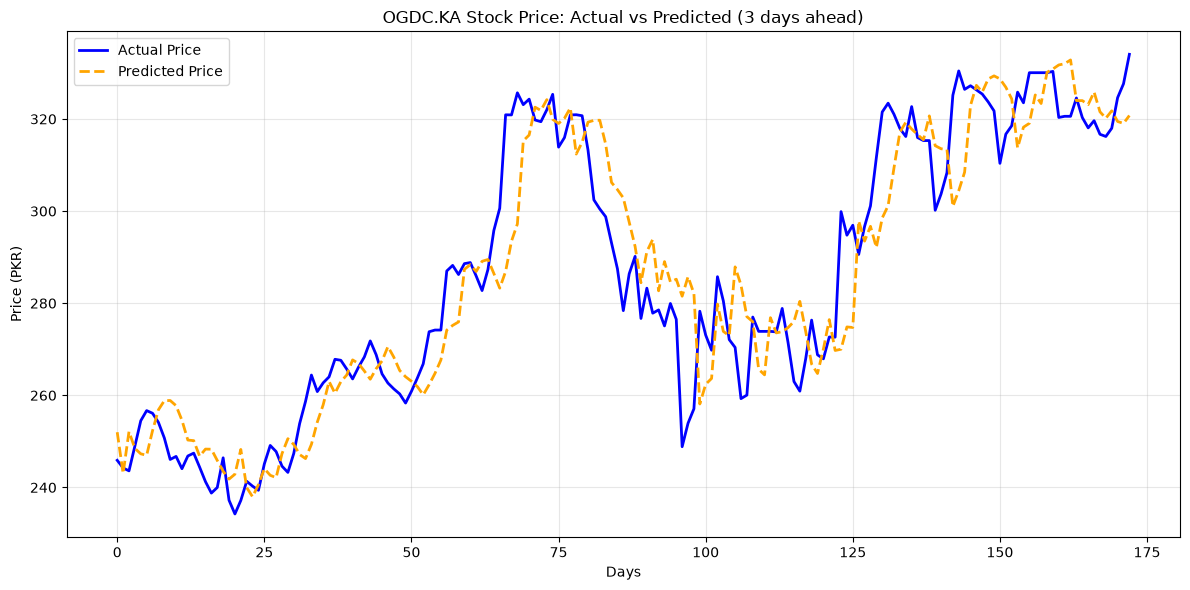

In [4]:
# ── Cell 3: Actual vs Predicted Plot ──
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(y_test.values,  label='Actual Price',    color='blue',   linewidth=2)
plt.plot(predictions,    label='Predicted Price', color='orange', linewidth=2, linestyle='--')
plt.title(f'OGDC.KA Stock Price: Actual vs Predicted ({days_ahead} days ahead)')
plt.xlabel('Days')
plt.ylabel('Price (PKR)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

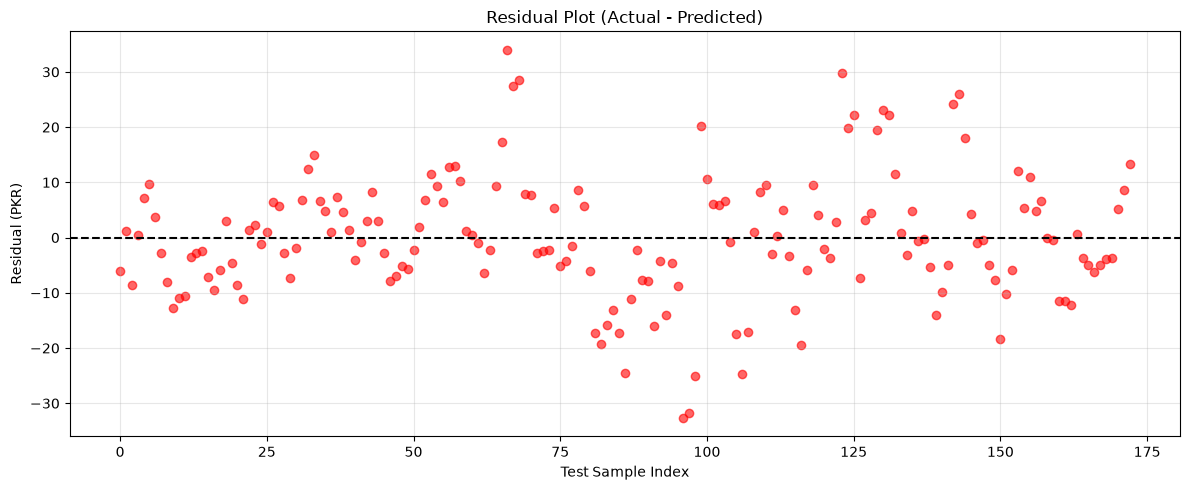

In [5]:
# ── Cell 4: Residual Plot ──
residuals = y_test.values - predictions

plt.figure(figsize=(12, 5))
plt.scatter(range(len(residuals)), residuals, alpha=0.6, color='red')
plt.axhline(y=0, color='black', linestyle='--', linewidth=1.5)
plt.title('Residual Plot (Actual - Predicted)')
plt.xlabel('Test Sample Index')
plt.ylabel('Residual (PKR)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


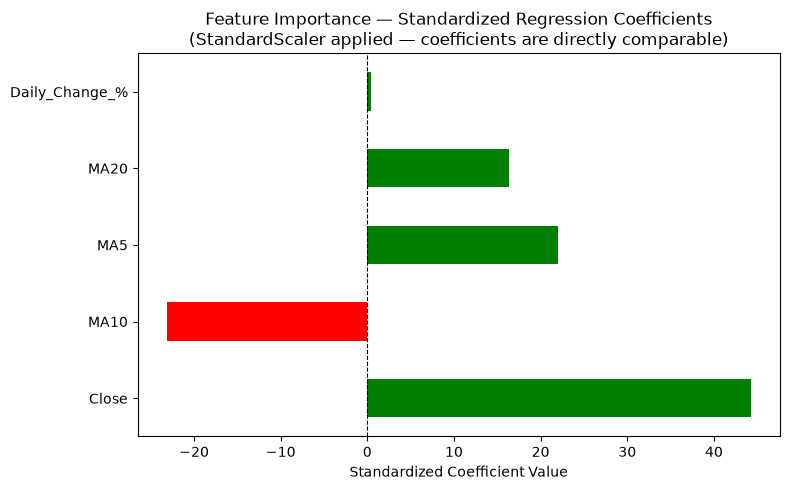


Feature Importance:
Close             44.255401
MA10             -23.127026
MA5               21.962651
MA20              16.326232
Daily_Change_%     0.401869
dtype: float64


In [6]:
# ── Cell 5: Feature Importance (after scaling — coefficients now comparable) ──
importance = pd.Series(model.coef_, index=features)
importance = importance.sort_values(key=abs, ascending=False)

colors = ['green' if c > 0 else 'red' for c in importance]

plt.figure(figsize=(8, 5))
importance.plot(kind='barh', color=colors)
plt.title('Feature Importance — Standardized Regression Coefficients\n(StandardScaler applied — coefficients are directly comparable)')
plt.xlabel('Standardized Coefficient Value')
plt.axvline(x=0, color='black', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

print("\nFeature Importance:")
print(importance)


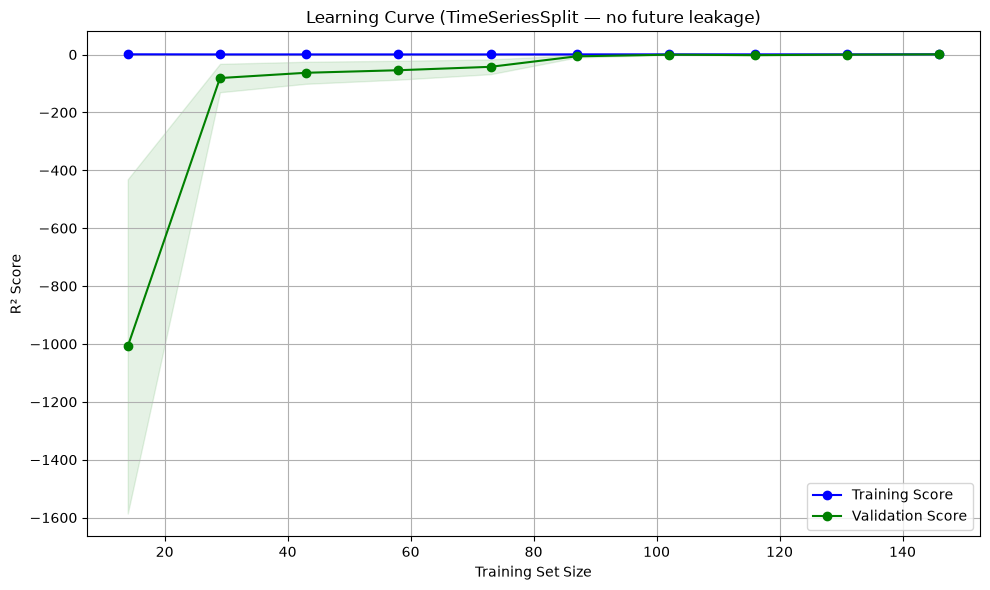

In [7]:
# ── Cell 6: Learning Curve with TimeSeriesSplit ──
from sklearn.model_selection import learning_curve, TimeSeriesSplit

# FIX: TimeSeriesSplit respects time order — no future data leaks into training
tscv = TimeSeriesSplit(n_splits=5)

train_sizes, train_scores, test_scores = learning_curve(
    LinearRegression(), X, y,
    cv=tscv,
    train_sizes=np.linspace(0.1, 1.0, 10),
    scoring='r2'
)

train_mean = train_scores.mean(axis=1)
test_mean  = test_scores.mean(axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', label='Training Score',    color='blue')
plt.plot(train_sizes, test_mean,  'o-', label='Validation Score',  color='green')
plt.fill_between(train_sizes,
                 train_scores.mean(axis=1) - train_scores.std(axis=1),
                 train_scores.mean(axis=1) + train_scores.std(axis=1),
                 alpha=0.1, color='blue')
plt.fill_between(train_sizes,
                 test_scores.mean(axis=1) - test_scores.std(axis=1),
                 test_scores.mean(axis=1) + test_scores.std(axis=1),
                 alpha=0.1, color='green')
plt.title('Learning Curve (TimeSeriesSplit — no future leakage)')
plt.xlabel('Training Set Size')
plt.ylabel('R² Score')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [8]:
# ── Cell 7: Model Comparison — LR vs DT vs RF ──
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

# All models trained on SCALED data
lr_model = LinearRegression()
dt_model = DecisionTreeRegressor(random_state=42)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

lr_model.fit(X_train_s, y_train)
dt_model.fit(X_train_s, y_train)
rf_model.fit(X_train_s, y_train)

lr_pred = lr_model.predict(X_test_s)
dt_pred = dt_model.predict(X_test_s)
rf_pred = rf_model.predict(X_test_s)

print("=" * 55)
print(f"{'Model':<20} {'R²':>8} {'MAE':>10} {'RMSE':>10}")
print("=" * 55)
for name, pred in [("Linear Regression", lr_pred),
                    ("Decision Tree",     dt_pred),
                    ("Random Forest",     rf_pred)]:
    r2_   = r2_score(y_test, pred)
    mae_  = mean_absolute_error(y_test, pred)
    rmse_ = np.sqrt(mean_squared_error(y_test, pred))
    print(f"{name:<20} {r2_:>8.4f} {mae_:>10.2f} {rmse_:>10.2f}")
print("=" * 55)


Model                      R²        MAE       RMSE
Linear Regression      0.8540       8.51      11.24
Decision Tree         -1.2130      36.24      43.75
Random Forest         -1.0427      33.66      42.03


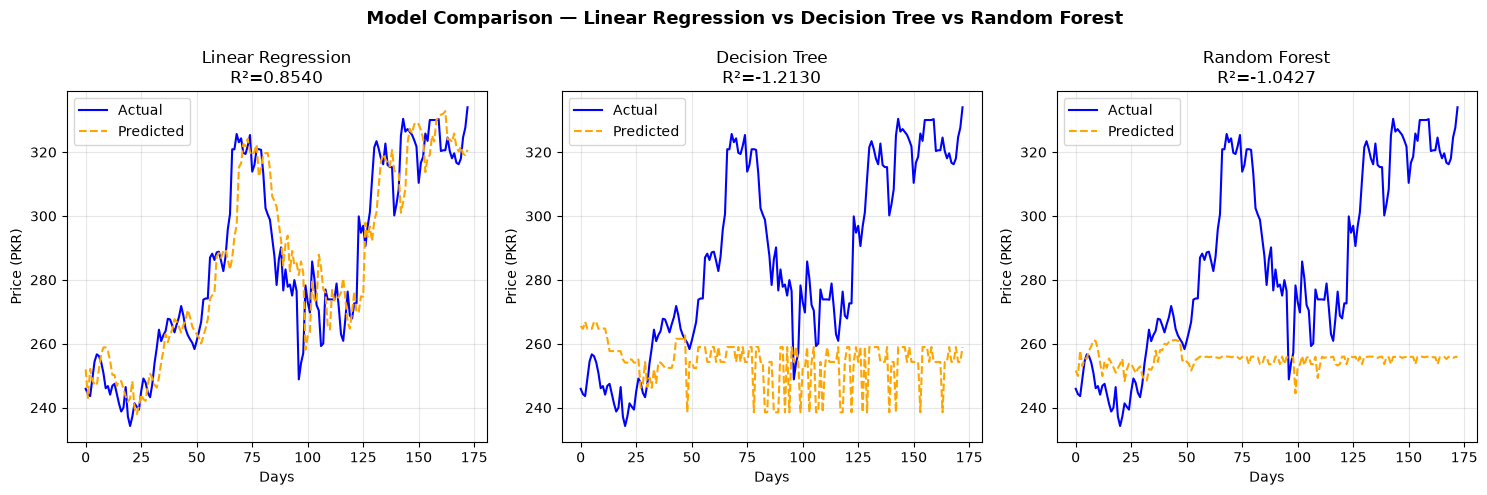

In [9]:
# ── Cell 8: Model Comparison Plot ──
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

models_list = [
    ("Linear Regression", lr_pred),
    ("Decision Tree",     dt_pred),
    ("Random Forest",     rf_pred)
]

for ax, (name, pred) in zip(axes, models_list):
    ax.plot(y_test.values, label='Actual',    color='blue',   linewidth=1.5)
    ax.plot(pred,          label='Predicted', color='orange', linewidth=1.5, linestyle='--')
    r2_ = r2_score(y_test, pred)
    ax.set_title(f"{name}\nR²={r2_:.4f}")
    ax.set_xlabel("Days")
    ax.set_ylabel("Price (PKR)")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle("Model Comparison — Linear Regression vs Decision Tree vs Random Forest",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [10]:
# ── Cell 9: Next Price Prediction with Confidence Range ──
# FIX: must transform latest row with SAME scaler used in training
X_latest      = scaler.transform(X.iloc[[-1]])
next_price     = lr_model.predict(X_latest)[0]
current_price  = float(data['Close'].iloc[-1])
change         = next_price - current_price
pct            = (change / current_price) * 100
low_range      = next_price - rmse
high_range     = next_price + rmse

print(f"\n{'='*40}")
print(f"Current Price        : {current_price:.2f} PKR")
print(f"Predicted ({days_ahead} days)   : {next_price:.2f} PKR")
print(f"Expected Change      : {change:+.2f} PKR ({pct:+.2f}%)")
print(f"Confidence Range     : {low_range:.2f} – {high_range:.2f} PKR")
print(f"{'='*40}")
print("⚠️  Educational use only. Not financial advice.")


Current Price        : 317.99 PKR
Predicted (3 days)   : 320.75 PKR
Expected Change      : +2.76 PKR (+0.87%)
Confidence Range     : 309.52 – 331.99 PKR
⚠️  Educational use only. Not financial advice.
